# <center>Taller de Aprendizaje Automático</center>
## <center>Taller 5: Clasificación binaria del Higgs con redes neuronales</center>

## Sub objetivos

Parte 2: Entrenar un modelo MLP de referencia con Keras para clasificación binaria.

Parte 3: Ajustar la arquitectura con una búsqueda manual pequeña y comparar variantes inspiradas en la guía del taller.


## Introducción

En este notebook se trabaja sobre el dataset procesado del desafío Higgs Boson. A diferencia del taller original de regresión, aquí el problema es de **clasificación binaria**: la etiqueta `Label` toma los valores `s` y `b`.

Se omite la sección de preprocesamiento antiguo y se parte directamente de los archivos ya preparados en `data/higgs-boson/processed/i1/`.

## Preparación de datos

Se cargan `X_train_processed.csv`, `y_train.csv`, `X_test_processed.csv` y `test_event_id.csv`. El dataset etiquetado se usa para armar `train/validación`, mientras que `X_test_processed` queda separado como conjunto externo sin etiquetas para inferencia final.

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


def find_processed_data_dir() -> Path:
    """Busca el directorio de datos procesados desde el cwd actual."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / "higgs-boson" / "processed" / "i1"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("No se encontro data/higgs-boson/processed/i1")


data_dir = find_processed_data_dir()
print(f"Data dir: {data_dir}")

I0000 00:00:1776524702.517750   98079 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776524702.594564   98079 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "
I0000 00:00:1776524704.483362   98079 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Data dir: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i1


In [2]:
X_labeled_full = pd.read_csv(data_dir / "X_train_processed.csv")
y_labeled_full = pd.read_csv(data_dir / "y_train.csv")
X_test_processed = pd.read_csv(data_dir / "X_test_processed.csv")
test_event_id = pd.read_csv(data_dir / "test_event_id.csv")

if list(X_labeled_full.columns) != list(X_test_processed.columns):
    raise ValueError("Las columnas de train y X_test_processed no coinciden.")

if len(X_test_processed) != len(test_event_id):
    raise ValueError("La cantidad de filas de X_test_processed y test_event_id no coincide.")

X = X_labeled_full.astype(np.float32)
y = y_labeled_full["Label"].map({"b": 0, "s": 1}).astype(np.int8)
X_test = X_test_processed.astype(np.float32)

print(f"X labeled shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X_test_processed shape: {X_test.shape}")
print(f"test_event_id shape: {test_event_id.shape}")
print("Class distribution:")
display(y.value_counts().rename(index={0: "b", 1: "s"}))
display(y.value_counts(normalize=True).rename(index={0: "b", 1: "s"}).rename("proportion"))

X labeled shape: (250000, 26)
y shape: (250000,)
X_test_processed shape: (550000, 26)
test_event_id shape: (550000, 1)
Class distribution:


Label
b    164333
s     85667
Name: count, dtype: int64

Label
b    0.657332
s    0.342668
Name: proportion, dtype: float64

## Train / validation split

Se reserva un 10% del dataset etiquetado para validación usando un split estratificado, para preservar la proporción de clases en ambos subconjuntos. `X_test_processed` no participa de este paso porque se mantiene como conjunto externo para inferencia.

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=SEED,
    stratify=y,
)

X_train_np = X_train.to_numpy(dtype=np.float32)
X_valid_np = X_valid.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)
y_train_np = y_train.to_numpy(dtype=np.float32)
y_valid_np = y_valid.to_numpy(dtype=np.float32)

classes = np.array([0, 1])
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_np.astype(int))
class_weight = {int(cls): float(weight) for cls, weight in zip(classes, class_weights)}

print(f"Train shape: {X_train_np.shape}")
print(f"Valid shape: {X_valid_np.shape}")
print(f"External test shape: {X_test_np.shape}")
print(f"Class weight: {class_weight}")

Train shape: (225000, 26)
Valid shape: (25000, 26)
External test shape: (550000, 26)
Class weight: {0: 0.7606490872210954, 1: 1.4591439688715953}


## Parte 2 - Baseline MLP

La red de referencia mantiene una estructura simple: una capa oculta densa y una capa final de clasificación con `sigmoid`. Para este problema se usa `binary_crossentropy` y métricas apropiadas para clasificación binaria.

In [4]:
INPUT_DIM = X_train_np.shape[1]
BASELINE_UNITS = 32


def build_baseline_model(input_dim: int = INPUT_DIM, learning_rate: float = 1e-3) -> keras.Model:
    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(BASELINE_UNITS, activation="relu", kernel_initializer="he_normal"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


baseline_model = build_baseline_model()
baseline_model.summary()

manual_params = (INPUT_DIM + 1) * BASELINE_UNITS + (BASELINE_UNITS + 1) * 1
print(f"Parametros entrenables (manual): {manual_params}")
print(f"Parametros entrenables (Keras): {baseline_model.count_params()}")

E0000 00:00:1776524711.001686   98079 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1776524711.002158   98203 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1776524711.023181   98079 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

Parametros entrenables (manual): 897
Parametros entrenables (Keras): 897


In [5]:
def make_callbacks() -> list[keras.callbacks.Callback]:
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
        ),
    ]

baseline_history = baseline_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=20,
    batch_size=1024,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=1,
)

baseline_eval = baseline_model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
print(baseline_eval)

Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6835 - auc: 0.7660 - loss: 0.5786 - precision: 0.5268 - recall: 0.7516 - val_accuracy: 0.7519 - val_auc: 0.8314 - val_loss: 0.5058 - val_precision: 0.6086 - val_recall: 0.7731 - learning_rate: 0.0010
Epoch 2/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7692 - auc: 0.8547 - loss: 0.4776 - precision: 0.6292 - recall: 0.7951 - val_accuracy: 0.7835 - val_auc: 0.8670 - val_loss: 0.4586 - val_precision: 0.6489 - val_recall: 0.8021 - learning_rate: 0.0010
Epoch 3/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7891 - auc: 0.8763 - loss: 0.4457 - precision: 0.6549 - recall: 0.8127 - val_accuracy: 0.7937 - val_auc: 0.8787 - val_loss: 0.4413 - val_precision: 0.6621 - val_recall: 0.8130 - learning_rate: 0.0010
Epoch 4/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7976 - auc: 0.8841 - loss: 0.4329 - precision: 0.6664 - recall: 0.8194 - val_accuracy: 0.8000 - val_auc: 0.8833 - val_loss: 0.4337 - val

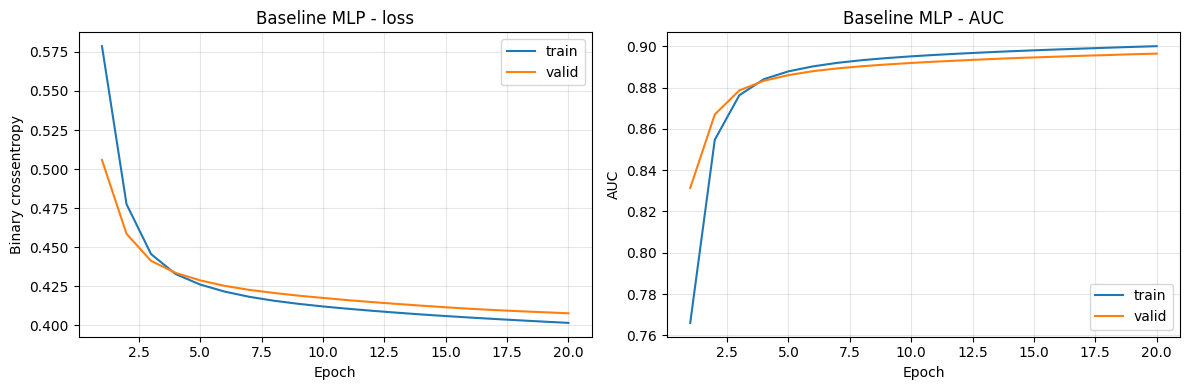

In [6]:
def plot_history(history, title: str) -> None:
    history_df = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df.index + 1, history_df["loss"], label="train")
    axes[0].plot(history_df.index + 1, history_df["val_loss"], label="valid")
    axes[0].set_title(f"{title} - loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history_df.index + 1, history_df["auc"], label="train")
    axes[1].plot(history_df.index + 1, history_df["val_auc"], label="valid")
    axes[1].set_title(f"{title} - AUC")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(baseline_history, "Baseline MLP")

## Parte 3 - Ajuste fino y comparación

En lugar de depender de `KerasTuner`, que en este entorno requiere componentes adicionales de `tensorboard`, se arma una búsqueda manual pequeña y reproducible sobre unas pocas configuraciones razonables.

La comparación incluye:
- cantidad de capas ocultas,
- cantidad de neuronas por capa,
- learning rate,
- y el tip del taller: evaluar si conviene que la primera capa sea más ancha que las siguientes.

In [7]:
def build_configurable_model(
    input_dim: int,
    n_hidden: int,
    n_units: int,
    learning_rate: float,
    first_layer_wider: bool,
) -> keras.Model:
    inputs = keras.layers.Input(shape=(input_dim,))
    x = inputs

    for layer_idx in range(n_hidden):
        units = n_units * 2 if first_layer_wider and layer_idx == 0 else n_units
        x = keras.layers.Dense(units, kernel_initializer="he_normal", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Activation("relu")(x)

    outputs = keras.layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


search_configs = [
    {
        "name": "cfg_1",
        "n_hidden": 1,
        "n_units": 64,
        "learning_rate": 1e-3,
        "first_layer_wider": False,
    },
    {
        "name": "cfg_2",
        "n_hidden": 2,
        "n_units": 64,
        "learning_rate": 1e-3,
        "first_layer_wider": True,
    },
    {
        "name": "cfg_3",
        "n_hidden": 2,
        "n_units": 128,
        "learning_rate": 5e-4,
        "first_layer_wider": False,
    },
    {
        "name": "cfg_4",
        "n_hidden": 3,
        "n_units": 96,
        "learning_rate": 5e-4,
        "first_layer_wider": True,
    },
]

pd.DataFrame(search_configs)

,name,n_hidden,n_units,learning_rate,first_layer_wider
0,cfg_1,1,64,0.0010,False
1,cfg_2,2,64,0.0010,True
2,cfg_3,2,128,0.0005,False
3,cfg_4,3,96,0.0005,True


In [8]:
search_results = []
search_histories = {}

for config in search_configs:
    tf.keras.backend.clear_session()
    model = build_configurable_model(
        input_dim=INPUT_DIM,
        n_hidden=config["n_hidden"],
        n_units=config["n_units"],
        learning_rate=config["learning_rate"],
        first_layer_wider=config["first_layer_wider"],
    )
    history = model.fit(
        X_train_np,
        y_train_np,
        validation_data=(X_valid_np, y_valid_np),
        epochs=12,
        batch_size=1024,
        class_weight=class_weight,
        callbacks=make_callbacks(),
        verbose=0,
    )
    metrics = model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
    search_results.append({**config, **metrics})
    search_histories[config["name"]] = history

search_results_df = pd.DataFrame(search_results).sort_values("auc", ascending=False).reset_index(drop=True)
best_config = search_results_df.iloc[0].to_dict()

print("Resultados de la búsqueda manual:")
display(search_results_df.round(4))
print("Mejor configuración encontrada:")
print(best_config)

Resultados de la búsqueda manual:


,name,n_hidden,n_units,learning_rate,first_layer_wider,accuracy,auc,loss,precision,recall
0,cfg_4,3,96,0.0005,True,0.8190,0.9027,0.3980,0.6987,0.8295
1,cfg_3,2,128,0.0005,False,0.8154,0.9023,0.4036,0.6886,0.8418
2,cfg_2,2,64,0.0010,True,0.8167,0.9011,0.4006,0.6954,0.8276
3,cfg_1,1,64,0.0010,False,0.8084,0.8947,0.4135,0.6810,0.8292


Mejor configuración encontrada:
{'name': 'cfg_4', 'n_hidden': 3, 'n_units': 96, 'learning_rate': 0.0005, 'first_layer_wider': True, 'accuracy': 0.8189600110054016, 'auc': 0.9027175307273865, 'loss': 0.398030549287796, 'precision': 0.6986530423164368, 'recall': 0.8294618725776672}


In [9]:
best_model = build_configurable_model(
    input_dim=INPUT_DIM,
    n_hidden=int(best_config["n_hidden"]),
    n_units=int(best_config["n_units"]),
    learning_rate=float(best_config["learning_rate"]),
    first_layer_wider=bool(best_config["first_layer_wider"]),
)

best_history = best_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=12,
    batch_size=1024,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

flipped_first_layer_model = build_configurable_model(
    input_dim=INPUT_DIM,
    n_hidden=int(best_config["n_hidden"]),
    n_units=int(best_config["n_units"]),
    learning_rate=float(best_config["learning_rate"]),
    first_layer_wider=not bool(best_config["first_layer_wider"]),
)

flipped_first_layer_history = flipped_first_layer_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=12,
    batch_size=1024,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

,accuracy,auc,loss,precision,recall
model,,,,,
best_manual_search,0.81848,0.902445,0.397100,0.698219,0.828295
same_hp_flipped_first_layer,0.82072,0.901386,0.393658,0.706835,0.814754
baseline,0.81332,0.896502,0.407807,0.689910,0.826894


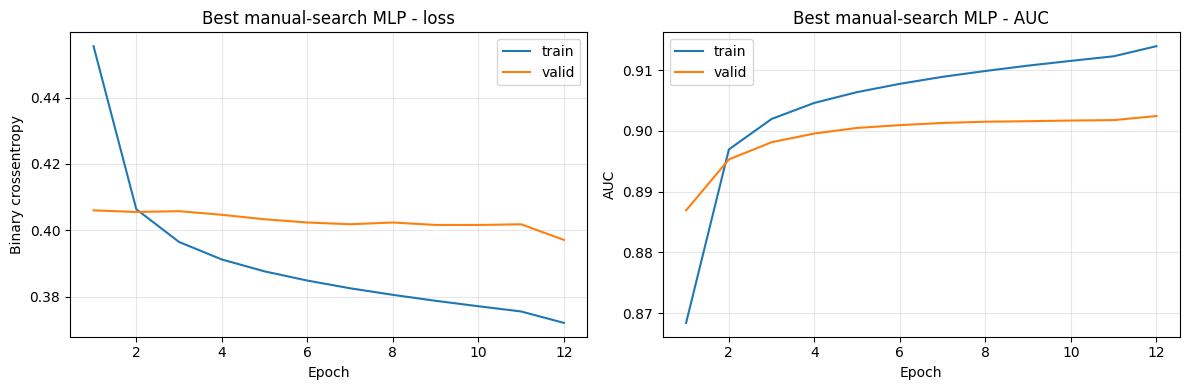

In [10]:
def final_metrics(model: keras.Model, name: str) -> dict:
    metrics = model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
    return {"model": name, **metrics}


comparison = pd.DataFrame([
    final_metrics(baseline_model, "baseline"),
    final_metrics(best_model, "best_manual_search"),
    final_metrics(flipped_first_layer_model, "same_hp_flipped_first_layer"),
])
comparison = comparison.set_index("model").sort_values("auc", ascending=False)
display(comparison)

plot_history(best_history, "Best manual-search MLP")

## Comparativa de resultados obtenidos

Esta sección consolida en un solo lugar los resultados de validación que vaya generando el notebook. La idea es poder comparar rápidamente:

- el `baseline`,
- la mejor configuración encontrada en la búsqueda manual,
- y la variante con los mismos hiperparámetros pero cambiando si la primera capa es más ancha o no.

Además de la tabla final, se muestran los deltas contra el baseline y una lectura rápida para decidir si la búsqueda manual realmente aportó algo.

Comparativa final de modelos en validacion:


,model,loss,accuracy,auc,precision,recall,delta_loss_vs_baseline,delta_accuracy_vs_baseline,delta_auc_vs_baseline,delta_precision_vs_baseline,delta_recall_vs_baseline
0,best_manual_search,0.3971,0.8185,0.9024,0.6982,0.8283,-0.0107,0.0052,0.0059,0.0083,0.0014
1,same_hp_flipped_first_layer,0.3937,0.8207,0.9014,0.7068,0.8148,-0.0141,0.0074,0.0049,0.0169,-0.0121
2,baseline,0.4078,0.8133,0.8965,0.6899,0.8269,0.0000,0.0000,0.0000,0.0000,0.0000


Resultados de la busqueda manual:


,name,n_hidden,n_units,learning_rate,first_layer_wider,loss,accuracy,auc,precision,recall
0,cfg_4,3,96,0.0005,True,0.3980,0.8190,0.9027,0.6987,0.8295
1,cfg_3,2,128,0.0005,False,0.4036,0.8154,0.9023,0.6886,0.8418
2,cfg_2,2,64,0.0010,True,0.4006,0.8167,0.9011,0.6954,0.8276
3,cfg_1,1,64,0.0010,False,0.4135,0.8084,0.8947,0.6810,0.8292


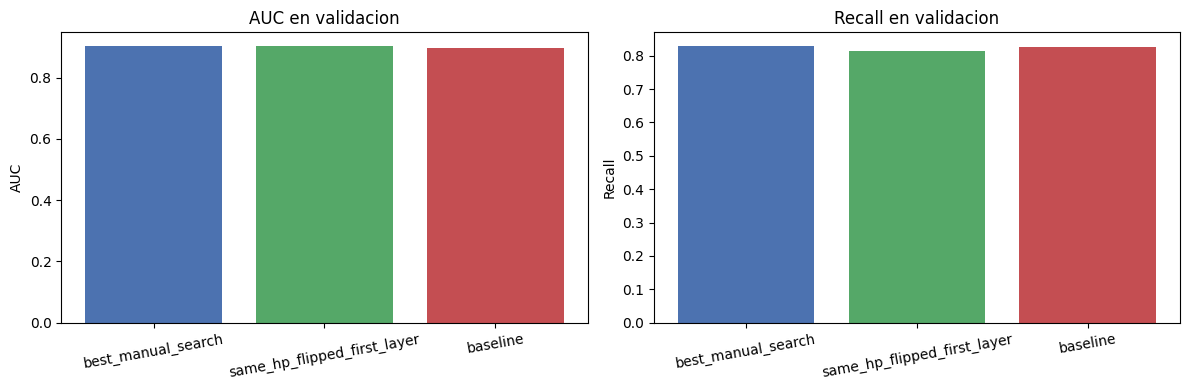

Lectura rapida:
- Mejor modelo por AUC: best_manual_search (0.9024).
- Delta AUC vs baseline: +0.0059.
- Delta recall vs baseline: +0.0014.
- Con los mismos hiperparametros, usar la primera capa mas ancha ayuda el AUC en +0.0011.


In [11]:
required_variables = ["baseline_eval", "search_results_df", "comparison"]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(
        "Faltan variables para la comparativa final. Ejecutar primero las partes 2 y 3 completas: "
        + ", ".join(missing_variables)
    )

metric_columns = ["loss", "accuracy", "auc", "precision", "recall"]

comparison_summary = comparison.reset_index().copy()
comparison_summary = comparison_summary[["model", *metric_columns]].copy()
comparison_summary = comparison_summary.drop_duplicates(subset=["model"], keep="first")
comparison_summary = comparison_summary.sort_values("auc", ascending=False).reset_index(drop=True)

baseline_row = comparison_summary.loc[comparison_summary["model"] == "baseline"]
if baseline_row.empty:
    baseline_row = pd.DataFrame([{"model": "baseline", **baseline_eval}])[ ["model", *metric_columns] ]
    comparison_summary = pd.concat([comparison_summary, baseline_row], ignore_index=True)
    comparison_summary = comparison_summary.drop_duplicates(subset=["model"], keep="first")
    comparison_summary = comparison_summary.sort_values("auc", ascending=False).reset_index(drop=True)
    baseline_row = comparison_summary.loc[comparison_summary["model"] == "baseline"]

baseline_metrics = baseline_row.iloc[0]
for metric in metric_columns:
    comparison_summary[f"delta_{metric}_vs_baseline"] = (
        comparison_summary[metric] - float(baseline_metrics[metric])
    )

search_columns = [
    column
    for column in [
        "name",
        "n_hidden",
        "n_units",
        "learning_rate",
        "first_layer_wider",
        "loss",
        "accuracy",
        "auc",
        "precision",
        "recall",
    ]
    if column in search_results_df.columns
]

print("Comparativa final de modelos en validacion:")
display(comparison_summary.round(4))

print("Resultados de la busqueda manual:")
display(search_results_df[search_columns].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bar_colors = ["#4C72B0", "#55A868", "#C44E52"][: len(comparison_summary)]

axes[0].bar(comparison_summary["model"], comparison_summary["auc"], color=bar_colors)
axes[0].set_title("AUC en validacion")
axes[0].set_ylabel("AUC")
axes[0].tick_params(axis="x", rotation=10)

axes[1].bar(comparison_summary["model"], comparison_summary["recall"], color=bar_colors)
axes[1].set_title("Recall en validacion")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

best_row = comparison_summary.iloc[0]
summary_lines = [
    f"Mejor modelo por AUC: {best_row['model']} ({best_row['auc']:.4f}).",
    f"Delta AUC vs baseline: {best_row['delta_auc_vs_baseline']:+.4f}.",
    f"Delta recall vs baseline: {best_row['delta_recall_vs_baseline']:+.4f}.",
]

candidate_models = {"best_manual_search", "same_hp_flipped_first_layer"}
if candidate_models.issubset(set(comparison_summary["model"])):
    wider_row = comparison_summary.loc[comparison_summary["model"] == "best_manual_search"].iloc[0]
    flipped_row = comparison_summary.loc[
        comparison_summary["model"] == "same_hp_flipped_first_layer"
    ].iloc[0]
    auc_gap = float(wider_row["auc"] - flipped_row["auc"])
    if auc_gap > 0:
        verdict = "ayuda"
    elif auc_gap < 0:
        verdict = "perjudica"
    else:
        verdict = "no cambia"
    summary_lines.append(
        f"Con los mismos hiperparametros, usar la primera capa mas ancha {verdict} el AUC en {auc_gap:+.4f}."
    )

print("Lectura rapida:")
for line in summary_lines:
    print(f"- {line}")

## Cierre

La salida de esta notebook deja un baseline funcional, una búsqueda manual acotada y una sección final que consolida la comparación entre variantes. El esquema correcto queda así: `train/validación` sobre el dataset etiquetado y `X_test_processed.csv` como conjunto externo sin etiquetas, listo para inferencia con el modelo elegido, no para entrenamiento.